# Performance Loss Analysis of the PLC Recording (CRISP-DM)

**Project:** Applied Industrial AI, mini-project 1 (performance loss)

**Notebook:** `notebooks/02_performance_loss_analysis.ipynb`
(generated from `scripts/performance_loss_analysis.py`, same code)

**Input:** `data/processed/siemens_cleaned.csv`,
`data/processed/beckhoff_cleaned.csv` and the variable file
`data/raw/Variablenerklärung.xlsx`

**Output:** CSV tables in `results/`, figures in `results/figures/`

**Explanation for the team / class:**
`docs/performance_loss_analysis.md`

**Rules of this analysis**

1. The cleaned data is never changed. Run all cells from top to bottom.
2. No hand-picked time windows. Every limit is either measured from the
   data or a textbook statistical rule, and it is printed.
3. Every statement is one of three kinds and is labelled as such:
   **documented** (variable file), **measured** (this data), or
   **open question** (cannot be decided from the data).
4. Every hypothesis has its test and decision rule written down
   **before** the result is computed.

## Phase 1 – Business understanding

### Task (slide 10 of the lecture)

"There are several performance losses reported (between 1 and 10) in
the production timeslot of the recorded data. Find them and allocate
them to a physical equipment."

### What is a performance loss? (slide 4, OEE)

OEE = Availability x Performance x Quality. Performance losses are the
"losses in speed" during up time. They have two forms:

- **Idle time and short stops:** the machine waits, nothing is broken.
- **Reduced speed:** the machine works, but slower than normal.

### Working definition used in this notebook

The machine repeats the same pallet cycle. Each actuator output (motor,
valve, drill) is switched ON for a typical time in every cycle. A
performance loss is a step that takes **clearly longer than the same
step normally takes**. "Clearly longer" is defined statistically in
Phase 4.

### Constraints (what the data can and cannot answer)

- One recording of about 506 s, two PLCs (Siemens S7, Beckhoff).
- No theoretical cycle time is given, so an OEE performance value in %
  **cannot** be calculated. We measure lost seconds instead.
- No labels (nobody marked the losses), so supervised learning is not
  possible. The detection must be unsupervised.
- The Siemens sheet of the variable file describes every signal. The
  Beckhoff sheet gives **only the station**, no description.
- Both PLCs log irregularly (about every 76 ms and 93 ms) with gaps up
  to 1.84 s. Effects shorter than the largest gap cannot be told apart
  from a logging gap.

### Hypotheses, tests and decision rules (fixed before testing)

Data understanding

- **H1** The two PLC clocks agree, so events can be compared across
  PLCs. *Test:* edges of a signal documented as going from Siemens to
  Beckhoff. *Accept if* every edge difference is within one median
  logging step of each PLC.
- **H2** The machine repeats one cycle with the same steps. *Test:*
  steps per pallet cycle. *Accept if* every complete cycle contains
  the same steps.

Modelling

- **H3** Losses appear as single activations that are far longer than
  normal. *Test:* Tukey fence on the ON-duration of every output.
  *Accept if* 1 to 10 events are found and the count does not change
  between the fences k = 1.5 and k = 3.

Evaluation

- **H4** The detections are real, not logging gaps or longer travel.
  *Accept if* every detection stays too long after subtracting the
  timing uncertainty, and is longer than the longest normal activation
  by at least the detection limit.
- **H5** During the extra time the equipment stands still (short stop)
  rather than moves slowly. *Test:* encoder pulses, paired output
  signals, sensor arrival times. *Decided per event.*
- **H6** The stops have a cause that is visible in the data (safety
  light curtain or HMI stop). *Decided per event.*
- **H7** The events make the pallet cycle longer. *Test:* exact
  permutation test, cycles with versus without event. *Accept if*
  p < 0.05.
- **H8** Nothing is missed: every unusually long period without any
  switching lies inside an event or a normal movement.

## Phase 2 – Data understanding

### Step 2.1 – Load the data and build one time axis

Time is converted from Unix milliseconds to **seconds since the first
Siemens row**, so both PLCs share the time axis `t`. No resampling and
no interpolation: each signal keeps its logged switching times.

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 70)

try:  # run as a script: python scripts/performance_loss_analysis.py
    PROJECT_DIR = Path(__file__).resolve().parents[1]
    IN_NOTEBOOK = False
except NameError:  # run in Jupyter, from notebooks/ or the project root
    PROJECT_DIR = Path.cwd()
    IN_NOTEBOOK = True
    if PROJECT_DIR.name == "notebooks":
        PROJECT_DIR = PROJECT_DIR.parent

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
VARIABLE_FILE = PROJECT_DIR / "data" / "raw" / "Variablenerklärung.xlsx"
RESULTS_DIR = PROJECT_DIR / "results"
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sie = pd.read_csv(PROCESSED_DIR / "siemens_cleaned.csv")
bec = pd.read_csv(PROCESSED_DIR / "beckhoff_cleaned.csv")
sie_doc = pd.read_excel(VARIABLE_FILE, sheet_name="Siemens")
bec_doc = pd.read_excel(VARIABLE_FILE, sheet_name="Beckhoff")

# One common time axis for both PLCs: seconds since the first Siemens row.
T0 = sie["timestamp"].iloc[0]
sie["t"] = (sie["timestamp"] - T0) / 1000
bec["t"] = (bec["timestamp"] - T0) / 1000
PLC = {"Siemens": sie, "Beckhoff": bec}
RECORDING_END = max(sie["t"].iloc[-1], bec["t"].iloc[-1])

print(f"Siemens : {len(sie)} rows, {sie.shape[1] - 2} signals")
print(f"Beckhoff: {len(bec)} rows, {bec.shape[1] - 2} signals")
print(f"Recording length: {RECORDING_END:.1f} s")

Siemens : 6282 rows, 142 signals
Beckhoff: 5197 rows, 53 signals
Recording length: 505.8 s


### Step 2.2 – Helper functions

- `on_intervals`: start and end of every ON-period of a boolean signal.
  One ON-period of an actuator output is called an **activation**.
- `edge_times`: the moments a signal switches.
- `step_before`: the logging step that ends at a given sample. It is
  the timing uncertainty of an edge at that sample.
- `describe`: station and meaning of a signal from the variable file.
- `show`: displays a figure in Jupyter (the script only saves it).

In [2]:
# Colours for all figures (grey = normal, orange = flagged as too long).
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e2dd"
C_NORMAL, C_FLAG = "#a8a69f", "#eb6834"
C_SAFETY, C_HMI = "#2a78d6", "#6250d6"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10,
})


def on_intervals(t, x):
    """Return (start, end) of every period in which boolean x is True.

    start = time of the first sample that is True,
    end = time of the first sample that is False again
    (or the last sample, if the signal is still True at the end).
    """
    t = np.asarray(t, dtype=float)
    x = np.asarray(x, dtype=bool).astype(int)
    change = np.diff(np.concatenate(([0], x, [0])))
    starts = np.flatnonzero(change == 1)
    ends = np.minimum(np.flatnonzero(change == -1), len(t) - 1)
    return [(float(t[a]), float(t[b])) for a, b in zip(starts, ends)]


def edge_times(t, x):
    """Return the times at which boolean x changes its value."""
    x = np.asarray(x, dtype=bool).astype(int)
    return np.asarray(t, dtype=float)[1:][np.diff(x) != 0]


def step_before(df, time):
    """Logging step (s) between the sample at `time` and the one before."""
    t = df["t"].to_numpy()
    i = int(np.clip(np.searchsorted(t, time), 1, len(t) - 1))
    return t[i] - t[i - 1]


def show(fig):
    """Display a figure in Jupyter; as a script, only close it."""
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close(fig)


def overlap(a_start, a_end, b_start, b_end):
    """True if the windows [a_start, a_end] and [b_start, b_end] share
    at least one moment."""
    return a_start <= b_end and b_start <= a_end


BEC_STATION = bec_doc.set_index("Variablenname / Beschreibung")["Station"]
SIE_DOC = sie_doc.set_index("Variablenname")
# Readable names for Beckhoff outputs. The variable file only gives the
# station, so these labels are a reading of the signal names.
BEC_LABEL = {
    "WH.Q1_beltForward": "conveyor belt forward",
    "WH.Q2_beltBackward": "conveyor belt backward",
    "WH.Q3_horRack": "horizontal axis towards rack",
    "WH.Q4_horBelt": "horizontal axis towards belt",
    "WH.Q7_cantForw": "cantilever forward",
    "WH.Q8_cantBack": "cantilever backward",
    "VG.Q7_compressorON": "compressor (one pick-and-place)",
}


def describe(signal):
    """Station and meaning of a signal, taken from the variable file."""
    if signal in SIE_DOC.index:
        row = SIE_DOC.loc[signal]
        text = row["Kommentar"].replace("(output)", "").strip()
        return f"{row['Station']}: {text} ({signal})"
    label = BEC_LABEL.get(signal, signal)
    return f"{BEC_STATION.get(signal, 'Beckhoff')}: {label} ({signal})"


print("helper functions ready")

helper functions ready


### Step 2.3 – Logging resolution: detection limit and sync tolerance

Two limits are **measured** here and used everywhere afterwards:

- **Detection limit** = the largest logging gap of both files. A step
  that is longer than normal by less than this could be caused by one
  missing stretch of log, so it is not reported as a loss.
- **Sync tolerance** = one median logging step of Siemens plus one of
  Beckhoff. Two loggers can each see the same switch up to one step
  late, so the same edge can differ by up to this amount between them.

In [3]:
rows = []
for name, df in PLC.items():
    step = df["t"].diff().dropna()
    rows.append({
        "PLC": name,
        "first_s": df["t"].iloc[0],
        "last_s": df["t"].iloc[-1],
        "median_step_s": step.median(),
        "max_step_s": step.max(),
        "steps_over_1s": int((step > 1).sum()),
    })
sampling = pd.DataFrame(rows).set_index("PLC")
print(sampling.round(3).to_string())

DETECTION_LIMIT_S = sampling["max_step_s"].max()
SYNC_TOLERANCE_S = sampling["median_step_s"].sum()
print(f"\nDetection limit = largest logging gap = {DETECTION_LIMIT_S:.2f} s")
print(f"Sync tolerance  = one median step of each PLC = "
      f"{SYNC_TOLERANCE_S:.3f} s")

          first_s   last_s  median_step_s  max_step_s  steps_over_1s
PLC                                                                 
Siemens      0.00  505.698          0.076       1.722              4
Beckhoff     0.41  505.804          0.093       1.841              1

Detection limit = largest logging gap = 1.84 s
Sync tolerance  = one median step of each PLC = 0.169 s


### Step 2.4 – What the variable file says about the key signals

Only documented meanings are used for interpretation. For Beckhoff
signals the file gives the station only, so the meaning of a Beckhoff
signal is a **reading of its name** and is marked as such.

In [4]:
USED_SIEMENS = ["A201.0", "M0.3", "AW256", "E200.0",
                "A1.0", "A0.7", "A1.7", "E1.0", "MD28", "MW32"]
print("Siemens signals used for interpretation (variable file):")
print(SIE_DOC.loc[USED_SIEMENS, ["Station", "Kommentar"]].to_string())

USED_BECKHOFF = ["VG.safeCurtainShort", "Visual.start", "Visual.Stoplight",
                 "WH.desiredPalletX", "WH.desiredPalletY",
                 "WH.I2_Light_barrier_inside", "WH.I3_Light_barrier_outside",
                 "WH.B1_encoder_horizontal_impuls1",
                 "WH.B2_encoder_horizontal_impuls2"]
print("\nBeckhoff sheet columns:", bec_doc.columns.tolist())
print("Beckhoff signals used (only the station is documented):")
print(BEC_STATION.loc[USED_BECKHOFF].to_string())

Siemens signals used for interpretation (variable file):
                        Station                            Kommentar
Variablenname                                                       
A201.0                 Beckhoff  Safetydata from curtain to beckhoff
M0.3             Balluff safety                     1 segment red ON
AW256            Balluff safety        data word that controls light
E200.0                 Beckhoff                Reset button from HMI
A1.0           Drilling station                    drill on (output)
A0.7           Drilling station                          conveyor on
A1.7           Drilling station              Suction on/off (output)
E1.0           Drilling station   lightbarrier in small belt (input)
MD28           Drilling station              Drilling time in second
MW32           Drilling station                   not in Time format

Beckhoff sheet columns: ['Variablenname / Beschreibung', 'Station']
Beckhoff signals used (only the station is doc

### Step 2.5 – Start of production

At the start of the recording the machine is not producing yet. The
production window is defined by a **documented** event: the first press
of the HMI reset button (`E200.0`, "Reset button from HMI"). Everything
before it (warehouse homing) is excluded.

In [5]:
reset_presses = [s for s, _ in on_intervals(sie["t"], sie["E200.0"])]
PRODUCTION_START = reset_presses[0]
homing = on_intervals(bec["t"], bec["WH.Q8_cantBack"])[0]
print("HMI reset button (E200.0) pressed at t =",
      [round(x, 2) for x in reset_presses])
print(f"First cantilever-back command (homing): "
      f"{homing[0]:.2f} to {homing[1]:.2f} s")
print(f"Production window: {PRODUCTION_START:.2f} s to "
      f"{RECORDING_END:.2f} s")

HMI reset button (E200.0) pressed at t = [8.93, 264.29, 400.44, 460.74]
First cantilever-back command (homing): 0.41 to 10.45 s
Production window: 8.93 s to 505.80 s


### Step 2.6 – H1: are the two PLC clocks in sync?

The pre-processing notebook could not estimate the clock offset from
overall activity (correlation 0.024). A more direct test exists: the
Siemens output `A201.0` is **documented** as "Safetydata from curtain
to beckhoff". The Beckhoff input `VG.safeCurtainShort` switches at the
same moments. If the clocks agree, each edge appears in both files at
the same time, within the sync tolerance.

In [6]:
sie_edges = edge_times(sie["t"], sie["A201.0"])
bec_edges = edge_times(bec["t"], bec["VG.safeCurtainShort"])
if len(sie_edges) != len(bec_edges):
    raise ValueError("The two safety signals do not have the same edges.")

clock = pd.DataFrame({
    "Siemens_A201.0_s": sie_edges,
    "Beckhoff_safeCurtainShort_s": bec_edges,
})
clock["difference_s"] = clock.iloc[:, 1] - clock.iloc[:, 0]
print(clock.round(3).to_string(index=False))

max_offset = clock["difference_s"].abs().max()
H1_ACCEPTED = bool(max_offset <= SYNC_TOLERANCE_S)
print(f"\nLargest difference: {max_offset:.3f} s "
      f"(tolerance {SYNC_TOLERANCE_S:.3f} s) -> H1 accepted: {H1_ACCEPTED}")

 Siemens_A201.0_s  Beckhoff_safeCurtainShort_s  difference_s
            8.851                        8.882         0.031
          255.396                      255.487         0.091
          264.292                      264.263        -0.029
          390.061                      390.100         0.039
          400.438                      400.396        -0.042
          453.141                      453.190         0.049
          460.743                      460.772         0.029

Largest difference: 0.091 s (tolerance 0.169 s) -> H1 accepted: True


**Result H1 (measured):** all 7 edges appear in both files, at most
0.09 s apart, which is within the sync tolerance of 0.169 s. The
differences change sign (the clocks do not drift apart). **H1 is
accepted:** no clock correction is needed, and Siemens and Beckhoff
events can be compared directly.

### Step 2.7 – H2: does the machine repeat the same cycle?

The Beckhoff signals `WH.desiredPalletX/Y` (warehouse, reading of the
name: requested rack position) change once per pallet. Each change
starts a **pallet cycle**. A cycle is **complete** if it starts after
the production start and the next request follows (the last cycle is
cut off by the end of the recording). The steps inside each cycle are
counted to check that the cycles are comparable.

In [7]:
REQUEST = ["WH.desiredPalletX", "WH.desiredPalletY"]
new_request = bec[REQUEST].diff().ne(0).any(axis=1)
cycles = bec.loc[new_request, ["t"] + REQUEST].reset_index(drop=True)
cycles.columns = ["start_s", "rack_x", "rack_y"]
cycles.insert(0, "cycle", range(1, len(cycles) + 1))
cycles["end_s"] = np.append(cycles["start_s"].to_numpy()[1:], RECORDING_END)
cycles["duration_s"] = cycles["end_s"] - cycles["start_s"]
cycles["complete"] = ((cycles["start_s"] >= PRODUCTION_START)
                      & (cycles["cycle"] < len(cycles)))


def count_starts(df, signal, start, end):
    """Number of ON-periods of `signal` that start in [start, end)."""
    starts = np.array([s for s, _ in on_intervals(df["t"], df[signal])])
    return int(((starts >= start) & (starts < end)).sum())


CYCLE_STEPS = {
    "belt_forward": "WH.Q1_beltForward",
    "belt_backward": "WH.Q2_beltBackward",
    "robot_moves": "VG.Q7_compressorON",
}
for column, signal in CYCLE_STEPS.items():
    cycles[column] = [count_starts(bec, signal, a, b)
                      for a, b in zip(cycles["start_s"], cycles["end_s"])]
print(cycles.round(1).to_string(index=False))

complete_cycles = cycles[cycles["complete"]]
same_structure = (
    (complete_cycles[list(CYCLE_STEPS)] == [1, 1, 2]).all(axis=1).all()
)
print("\nTotal activations over the whole recording:")
for plc, signal in [("Beckhoff", "WH.Q1_beltForward"),
                    ("Beckhoff", "WH.Q2_beltBackward"),
                    ("Siemens", "A1.1"), ("Siemens", "A1.2"),
                    ("Siemens", "A1.0"), ("Siemens", "A0.7"),
                    ("Siemens", "A1.7")]:
    n = len(on_intervals(PLC[plc]["t"], PLC[plc][signal]))
    print(f"  {describe(signal):60s} {n}")
H2_ACCEPTED = bool(same_structure)
print(f"\nAll {len(complete_cycles)} complete cycles have 1 belt forward, "
      f"1 belt backward, 2 robot moves -> H2 accepted: {H2_ACCEPTED}")

 cycle  start_s  rack_x  rack_y  end_s  duration_s  complete  belt_forward  belt_backward  robot_moves
     1      0.4    1620     110   45.4        45.0     False             1              1            1
     2     45.4     910     110   98.5        53.1      True             1              1            2
     3     98.5    2330     540  156.1        57.6      True             1              1            2
     4    156.1    1640     540  210.1        53.9      True             1              1            2
     5    210.1     910     540  273.1        63.1      True             1              1            2
     6    273.1    2330    1030  336.3        63.1      True             1              1            2
     7    336.3    1620    1030  404.4        68.2      True             1              1            2
     8    404.4     910    1030  453.0        48.6      True             1              1            2
     9    453.0    2330     110  505.8        52.8     False             

**Result H2 (measured):**

- 9 pallet requests. Cycles 2 to 8 are complete. Cycle 1 contains the
  start-up (and only 1 robot move, because no finished part exists
  yet). Cycle 9 is cut off by the end of the recording.
- Every complete cycle has exactly 1 belt forward, 1 belt backward and
  2 robot pick-and-place moves. The drilling station runs each of its
  steps 9 times in total, once per part.
- **H2 is accepted:** the steps repeat, so "how long does this step
  normally take" is a meaningful question.
- Note: the rack position changes from cycle to cycle, so travel times
  of the warehouse axes vary by design. This is tested in H4.

## Phase 3 – Data preparation

### Step 3.1 – Activation table

Only **actuator outputs** are analysed, because only they can be
"too long":

- Siemens: all signals whose name starts with `A` and whose station is
  the sorting or drilling station (documented outputs). Data words to
  the Beckhoff PLC and safety lamp outputs are excluded.
- Beckhoff: all signals with `.Q` in the name. `Q` is the IEC 61131-3
  notation for an output (the variable file gives no description).

Every ON-period of every output becomes one row: signal, start, end,
duration. Only activations that start in the production window are
kept.

In [8]:
sie_actuators = sie_doc.loc[
    sie_doc["Variablenname"].str.startswith("A")
    & sie_doc["Station"].isin(["Sorting station", "Drilling station"]),
    "Variablenname",
].tolist()
bec_actuators = [c for c in bec.columns if ".Q" in c]

rows = []
for plc, signals in (("Siemens", sie_actuators), ("Beckhoff", bec_actuators)):
    df = PLC[plc]
    for signal in signals:
        for start, end in on_intervals(df["t"], df[signal]):
            rows.append((plc, signal, start, end))
acts = pd.DataFrame(rows, columns=["plc", "signal", "start", "end"])
acts["duration"] = acts["end"] - acts["start"]
acts = acts[acts["start"] >= PRODUCTION_START].reset_index(drop=True)

never_on = sorted(set(sie_actuators + bec_actuators) - set(acts["signal"]))
print(f"Actuator outputs: {len(sie_actuators)} Siemens, "
      f"{len(bec_actuators)} Beckhoff")
print(f"Activations in the production window: {len(acts)} "
      f"from {acts['signal'].nunique()} outputs")
print("Outputs that never switch on:", never_on)
print("\nFirst rows of the activation table:")
print(acts.head().round(2).to_string(index=False))

Actuator outputs: 19 Siemens, 22 Beckhoff
Activations in the production window: 677 from 41 outputs
Outputs that never switch on: []

First rows of the activation table:
    plc signal  start    end  duration
Siemens   A0.0  22.18  25.08      2.90
Siemens   A0.0  25.47  29.42      3.95
Siemens   A0.0  51.37  53.90      2.53
Siemens   A0.0  54.52  57.69      3.18
Siemens   A0.0 123.22 125.82      2.60


## Phase 4 – Modelling: detecting activations that are too long

### Step 4.1 – H3: the detection rule

For each output, the normal duration is described by robust statistics
that one long value cannot distort: the **median** and the
**interquartile range** IQR = Q3 - Q1. An activation is flagged if

1. its duration is above **Tukey's fence** Q3 + k x IQR, with the
   textbook value k = 3 ("far out" values), and
2. it is longer than the median by at least the **detection limit**
   (1.84 s, measured in Step 2.3).

Outputs with fewer than 5 activations are skipped, because quartiles of
fewer values are not meaningful (their effect is checked below).

Flagged activations that **overlap in time** form one **event**. No
time gap parameter is needed for this.

In [9]:
TUKEY_K = 3.0          # Tukey's "far out" fence: Q3 + 3 * IQR
MIN_ACTIVATIONS = 5    # quartiles need at least 5 values to be meaningful


def normal_durations(acts):
    """Median, quartiles and maximum of the ON-duration per output."""
    grouped = acts.groupby("signal")["duration"]
    stats = pd.DataFrame({
        "n": grouped.size(),
        "median": grouped.median(),
        "q1": grouped.quantile(0.25),
        "q3": grouped.quantile(0.75),
        "max": grouped.max(),
    })
    stats["iqr"] = stats["q3"] - stats["q1"]
    return stats


def flag_long(acts, stats, k=TUKEY_K, limit=DETECTION_LIMIT_S):
    """Activations above the Tukey fence and longer than normal by at
    least `limit` seconds."""
    data = acts.join(stats[["n", "median", "q3", "iqr"]], on="signal")
    data["fence"] = data["q3"] + k * data["iqr"]
    data["excess"] = data["duration"] - data["median"]
    is_long = ((data["n"] >= MIN_ACTIVATIONS)
               & (data["duration"] > data["fence"])
               & (data["excess"] >= limit))
    return data[is_long].sort_values("start").reset_index(drop=True)


def group_overlapping(flags):
    """Give overlapping flagged activations the same event number."""
    numbers, number, group_end = [], 0, -np.inf
    for start, end in zip(flags["start"], flags["end"]):
        if start > group_end:  # no overlap with the current event
            number += 1
            group_end = end
        group_end = max(group_end, end)
        numbers.append(number)
    return numbers


stats = normal_durations(acts)
flags = flag_long(acts, stats)
flags["event"] = [f"E{n}" for n in group_overlapping(flags)]
flag_keys = set(zip(flags["signal"], flags["start"]))
print(flags[["event", "plc", "signal", "start", "end", "duration",
             "median", "fence", "excess"]].round(2).to_string(index=False))
print(f"\n{len(flags)} long activations -> {flags['event'].nunique()} events")

event      plc             signal  start    end  duration  median  fence  excess
   E1 Beckhoff      WH.Q3_horRack 252.42 266.03     13.61    3.10   9.64   10.50
   E1  Siemens               A1.7 254.15 272.17     18.03    9.22   9.44    8.80
   E2 Beckhoff  WH.Q1_beltForward 291.28 299.08      7.80    0.86   1.29    6.94
   E3 Beckhoff WH.Q2_beltBackward 314.84 321.63      6.79    0.57   0.74    6.22
   E4 Beckhoff  WH.Q1_beltForward 350.80 360.42      9.62    0.86   1.29    8.77
   E5  Siemens               A0.7 363.10 371.09      7.99    5.77   6.75    2.21
   E6  Siemens               A1.0 385.07 390.14      5.07    0.99   1.22    4.08
   E6 Beckhoff     WH.Q7_cantForw 387.44 400.86     13.43    3.06   3.30   10.37
   E7 Beckhoff      WH.Q3_horRack 452.99 463.28     10.29    3.10   9.64    7.19
   E8 Beckhoff     WH.Q8_cantBack 468.45 476.48      8.03    3.11   3.21    4.92

10 long activations -> 8 events


### Step 4.2 – How sensitive is the result to the two settings?

The rule has two settings: the fence factor k and the minimum excess.
Both are varied. The outputs skipped for having fewer than 5
activations are listed with their largest excess.

In [10]:
sensitivity = []
for k in (1.5, 3.0):
    for limit in (1.0, DETECTION_LIMIT_S, 3.0):
        found = flag_long(acts, stats, k=k, limit=limit)
        sensitivity.append({
            "tukey_k": k,
            "min_excess_s": round(limit, 2),
            "long_activations": len(found),
            "events": len(set(group_overlapping(found))),
        })
sensitivity = pd.DataFrame(sensitivity)
print(sensitivity.to_string(index=False))

few = stats[stats["n"] < MIN_ACTIVATIONS].copy()
few["max_excess"] = few["max"] - few["median"]
print(f"\nOutputs skipped (fewer than {MIN_ACTIVATIONS} activations):")
print(few[["n", "median", "max", "max_excess"]].round(2).to_string())

wide = stats[stats["iqr"] > DETECTION_LIMIT_S]
print("\nOutputs whose normal duration itself varies by more than the "
      "detection limit (IQR):")
print(wide[["n", "median", "q1", "q3", "max"]].round(2).to_string())

n_events = flags["event"].nunique()
at_limit = sensitivity[sensitivity["min_excess_s"]
                       == round(DETECTION_LIMIT_S, 2)]
stable = at_limit["events"].nunique() == 1
H3_ACCEPTED = bool((1 <= n_events <= 10) and stable)
print(f"\n{n_events} events, same count for k = 1.5 and k = 3: {stable} "
      f"-> H3 accepted: {H3_ACCEPTED}")

 tukey_k  min_excess_s  long_activations  events
     1.5          1.00                29      16
     1.5          1.84                10       8
     1.5          3.00                 9       7
     3.0          1.00                14      10
     3.0          1.84                10       8
     3.0          3.00                 9       7

Outputs skipped (fewer than 5 activations):
        n  median   max  max_excess
signal                             
A0.2    4    0.53  0.54        0.01
A0.3    3    0.46  0.50        0.04
A0.4    3    0.54  1.87        1.32

Outputs whose normal duration itself varies by more than the detection limit (IQR):
                     n  median     q1     q3    max
signal                                             
A1.6                10   29.68  22.43  44.27  54.64
A4.1                 9   52.02  39.46  64.54  74.29
VG.Q7_compressorON  16    7.77   6.65   9.23   9.79

8 events, same count for k = 1.5 and k = 3: True -> H3 accepted: True


**Result H3 (measured):**

- 677 activations of 41 outputs were tested. **10 activations** are
  too long. They form **8 events** (E1 to E8), inside the 1 to 10
  given in the task.
- At the detection limit the result is the same for k = 1.5 and k = 3.
  Below the detection limit (1 s) many more small deviations appear,
  which cannot be separated from logging gaps. Above it (3 s) only the
  weakest event E5 (+2.2 s) disappears.
- The skipped outputs (sorting pushers) never exceed their median by
  more than 1.32 s, so skipping them changes nothing.
- Limit of the rule: for the compressor `A1.6` and the oven door
  `A4.1` the normal duration varies by tens of seconds (they hold a
  state while other steps run), so the rule cannot judge them. The
  robot compressor has two normal lengths (short and long move); its
  wide fence is correct and none of its activations is flagged.
- **H3 is accepted.**

## Phase 5 – Evaluation

### Step 5.1 – H4: are the detections real?

Two alternative explanations are tested for each flagged activation.

- **Logging artefact.** Each edge can be off by the logging step before
  it. Both uncertainties are subtracted from the excess. If something
  is left, the activation was too long even in the worst case.
- **Longer travel (rack position).** The activation is compared with
  the **longest normal** activation of the same output. That one
  already includes the farthest rack position in the recording.

In [11]:
flags["edge_uncertainty_s"] = [
    step_before(PLC[p], s) + step_before(PLC[p], e)
    for p, s, e in zip(flags["plc"], flags["start"], flags["end"])
]
flags["worst_case_excess_s"] = flags["excess"] - flags["edge_uncertainty_s"]

is_flagged = np.array([k in flag_keys
                       for k in zip(acts["signal"], acts["start"])])
longest_normal = acts[~is_flagged].groupby("signal")["duration"].max()
flags["longest_normal_s"] = flags["signal"].map(longest_normal)
flags["above_longest_normal_s"] = (flags["duration"]
                                   - flags["longest_normal_s"])

print(flags[["event", "signal", "duration", "edge_uncertainty_s",
             "worst_case_excess_s", "longest_normal_s",
             "above_longest_normal_s"]].round(2).to_string(index=False))
H4_ACCEPTED = bool(
    (flags["worst_case_excess_s"] > 0).all()
    and (flags["above_longest_normal_s"] >= DETECTION_LIMIT_S).all()
)
print(f"\nH4 accepted (all detections are real, not gaps or distance): "
      f"{H4_ACCEPTED}")

event             signal  duration  edge_uncertainty_s  worst_case_excess_s  longest_normal_s  above_longest_normal_s
   E1      WH.Q3_horRack     13.61                0.17                10.33              4.38                    9.23
   E1               A1.7     18.03                0.15                 8.65              9.26                    8.76
   E2  WH.Q1_beltForward      7.80                0.19                 6.75              0.96                    6.84
   E3 WH.Q2_beltBackward      6.79                0.19                 6.04              0.65                    6.14
   E4  WH.Q1_beltForward      9.62                0.21                 8.56              0.96                    8.66
   E5               A0.7      7.99                0.15                 2.06              6.03                    1.96
   E6               A1.0      5.07                0.15                 3.93              1.05                    4.02
   E6     WH.Q7_cantForw     13.43                0.18  

**Result H4 (measured):** the edge uncertainty is at most 0.21 s, so
every detection stays clearly too long (worst case still +2.1 s to
+10.3 s). Every detection is also longer than the longest normal
activation of the same output by at least the detection limit, so a
far rack position cannot explain it. The weakest case is again E5
(+1.96 s above the longest normal run). **H4 is accepted.**

### Step 5.2 – H5: standstill or slow motion? (a) paired outputs

The Beckhoff file contains two signals for every warehouse motor
direction, for example `WH.Q3_horRack` and
`WH.Q3_horizontal_towards_rack`. The variable file does not explain the
difference. We **measure** how they behave: windows in which the first
is ON and its partner is OFF.

In [12]:
PAIRS = {
    "WH.Q3_horRack": "WH.Q3_horizontal_towards_rack",
    "WH.Q4_horBelt": "WH.Q4_horizontal_towards_conveyor_belt",
    "WH.Q5_verDown": "WH.Q5_vertical_downward",
    "WH.Q6_verUP": "WH.Q6_vertical_upward",
    "WH.Q7_cantForw": "WH.Q7_cantilever_forward",
    "WH.Q8_cantBack": "WH.Q8_cantilever_backward",
}
rows = []
for first, second in PAIRS.items():
    only_first = bec[first] & ~bec[second]
    for start, end in on_intervals(bec["t"], only_first):
        if start >= PRODUCTION_START:
            rows.append((first, second, start, end, end - start))
mismatch = pd.DataFrame(
    rows, columns=["first", "second", "start", "end", "duration"])
drive_off = mismatch[mismatch["duration"] >= DETECTION_LIMIT_S]
shorter = mismatch.loc[mismatch["duration"] < DETECTION_LIMIT_S, "duration"]

print(f"Windows with the first signal ON and its partner OFF: "
      f"{len(mismatch)}")
print(f"  shorter than the detection limit: {len(shorter)} "
      f"(longest {shorter.max():.2f} s)")
print(f"  longer than the detection limit:  {len(drive_off)}")
print(drive_off.round(2).to_string(index=False))

Windows with the first signal ON and its partner OFF: 111
  shorter than the detection limit: 107 (longest 0.26 s)
  longer than the detection limit:  4
         first                        second  start    end  duration
 WH.Q3_horRack WH.Q3_horizontal_towards_rack 252.42 264.26     11.84
 WH.Q3_horRack WH.Q3_horizontal_towards_rack 453.09 460.68      7.58
WH.Q7_cantForw      WH.Q7_cantilever_forward 390.10 400.40     10.30
WH.Q8_cantBack     WH.Q8_cantilever_backward 468.45 473.34      4.89


**Measured:** in normal operation the two signals of a pair switch
within 0.26 s of each other (107 short windows). Only 4 windows are
long (4.9 to 11.8 s). In these the first signal stays ON while its
partner is OFF. They lie inside events E1, E6, E7 and E8.

The encoder test in the next step shows that the axis does not move
while the partner signal is OFF. So the partner behaves like the
**motor output** and the first signal like the **request** (a reading
that is consistent with the data, not documented).

### Step 5.3 – H5 (b) encoder pulses of the horizontal axis

The horizontal warehouse axis has two encoder channels
(`WH.B1/B2_encoder_horizontal_impuls`). A moving axis produces encoder
edges. For every horizontal move, the longest time without any encoder
edge is measured.

Note: the logger samples only about 11 times per second, which is close
to the pulse rate. Pulse **counts** are therefore not a reliable speed
measure. Only "pulses present / no pulse for seconds" is used.

In [13]:
ENCODERS = ["WH.B1_encoder_horizontal_impuls1",
            "WH.B2_encoder_horizontal_impuls2"]
pulse_times = np.sort(np.concatenate(
    [edge_times(bec["t"], bec[c]) for c in ENCODERS]))


def longest_silence(start, end):
    """Longest time inside [start, end] without any encoder edge."""
    inside = pulse_times[(pulse_times > start) & (pulse_times < end)]
    return float(np.diff(np.concatenate(([start], inside, [end]))).max())


moves = acts[acts["signal"].isin(["WH.Q3_horRack", "WH.Q4_horBelt"])].copy()
moves["longest_silence_s"] = [longest_silence(s, e)
                              for s, e in zip(moves["start"], moves["end"])]
moves["flagged"] = [k in flag_keys
                    for k in zip(moves["signal"], moves["start"])]
print(moves[["signal", "start", "duration", "longest_silence_s",
             "flagged"]].round(2).to_string(index=False))
normal_silence = moves.loc[~moves["flagged"], "longest_silence_s"].max()
print(f"\nLongest encoder silence in a normal move: {normal_silence:.2f} s")

       signal  start  duration  longest_silence_s  flagged
WH.Q3_horRack  34.39      3.06               0.37    False
WH.Q3_horRack  88.66      1.74               0.56    False
WH.Q3_horRack  98.50      2.57               0.19    False
WH.Q3_horRack 144.71      4.38               0.28    False
WH.Q3_horRack 199.87      3.15               0.30    False
WH.Q3_horRack 252.42     13.61              11.84     True
WH.Q3_horRack 273.14      2.63               0.37    False
WH.Q3_horRack 325.23      4.34               0.32    False
WH.Q3_horRack 384.43      3.01               0.56    False
WH.Q3_horRack 444.53      1.79               0.27    False
WH.Q3_horRack 452.99     10.29               7.58     True
WH.Q3_horRack 497.87      4.37               0.88    False
WH.Q4_horBelt  12.02      3.07               0.38    False
WH.Q4_horBelt  45.43      1.41               0.28    False
WH.Q4_horBelt  54.76      1.74               0.26    False
WH.Q4_horBelt 109.01      4.47               0.56    Fal



Longest encoder silence in a normal move: 0.88 s


**Measured:** in the 24 normal horizontal moves the encoder is never
silent for more than 0.88 s. In the two flagged moves it is silent for
**11.84 s (E1)** and **7.58 s (E7)**, exactly as long as the motor
output of the pair was OFF. The axis **stood still**, it did not move
slowly.

### Step 5.4 – H5 (c) belt and small conveyor: when does the part
arrive?

The warehouse belt and the small conveyor of the drilling station have
**no** encoder. What can be measured is when the transported part
reaches the light barrier at the destination:

- Warehouse belt: the last change of the light barriers
  `WH.I2` (inside) / `WH.I3` (outside) during the belt run.
- Small conveyor: the first change of `E1.0` ("lightbarrier in small
  belt", documented) during the conveyor run.

We also check whether the outside barrier changes while the belt is
**not** running.

In [14]:
barrier_edges = np.sort(np.concatenate([
    edge_times(bec["t"], bec[c])
    for c in ("WH.I2_Light_barrier_inside", "WH.I3_Light_barrier_outside")
]))
belt = acts[acts["signal"].isin(
    ["WH.Q1_beltForward", "WH.Q2_beltBackward"])].copy()
last_barrier = np.array([
    barrier_edges[(barrier_edges >= s) & (barrier_edges <= e)].max()
    for s, e in zip(belt["start"], belt["end"])
])
belt["barrier_reached_after_s"] = last_barrier - belt["start"]
belt["belt_off_after_barrier_s"] = belt["end"] - last_barrier
belt["flagged"] = [k in flag_keys for k in zip(belt["signal"], belt["start"])]
print(belt[["signal", "start", "duration", "barrier_reached_after_s",
            "belt_off_after_barrier_s", "flagged"]]
      .round(2).to_string(index=False))

belt_on = bec["WH.Q1_beltForward"] | bec["WH.Q2_beltBackward"]
belt_off_both = ~belt_on & ~belt_on.shift(fill_value=True)
for barrier in ("WH.I2_Light_barrier_inside", "WH.I3_Light_barrier_outside"):
    changed = bec[barrier].astype(int).diff().fillna(0).ne(0)
    times = bec.loc[changed & belt_off_both
                    & (bec["t"] >= PRODUCTION_START), "t"]
    print(f"\n{barrier} changes while both belt outputs are OFF "
          f"({len(times)}x):", times.round(2).tolist())

            signal  start  duration  barrier_reached_after_s  belt_off_after_barrier_s  flagged
 WH.Q1_beltForward  18.57      0.91                     0.46                      0.45    False
 WH.Q1_beltForward  60.05      0.85                     0.54                      0.31    False
 WH.Q1_beltForward 117.02      0.85                     0.43                      0.42    False
 WH.Q1_beltForward 171.24      0.80                     0.43                      0.37    False
 WH.Q1_beltForward 223.73      0.86                     0.48                      0.38    False
 WH.Q1_beltForward 291.28      7.80                     7.51                      0.28     True
 WH.Q1_beltForward 350.80      9.62                     9.34                      0.29     True
 WH.Q1_beltForward 417.69      0.74                     0.43                      0.31    False
 WH.Q1_beltForward 485.87      0.96                     0.58                      0.38    False
WH.Q2_beltBackward  30.14      0.55     

In [15]:
part_edges = edge_times(sie["t"], sie["E1.0"])
conveyor = acts[acts["signal"] == "A0.7"].copy()
first_edge = []
for s, e in zip(conveyor["start"], conveyor["end"]):
    inside = part_edges[(part_edges >= s) & (part_edges <= e)]
    first_edge.append(inside.min() - s if len(inside) else np.nan)
conveyor["part_at_barrier_after_s"] = first_edge
conveyor["flagged"] = [k in flag_keys
                       for k in zip(conveyor["signal"], conveyor["start"])]
print(conveyor[["signal", "start", "duration", "part_at_barrier_after_s",
                "flagged"]].round(2).to_string(index=False))

print("\nDrill time variables: every change of value in the recording")
for variable in ("MD28", "MW32"):
    changed = sie[variable].diff().fillna(0).ne(0)
    print(f"  {variable}: changes at t =",
          sie.loc[changed, "t"].round(2).tolist())
drill = acts[acts["signal"] == "A1.0"]
print("Drill (A1.0) ON-durations:", drill["duration"].round(2).tolist())

signal  start  duration  part_at_barrier_after_s  flagged
  A0.7  50.46      5.77                     0.99    False
  A0.7 122.38      5.60                     0.84    False
  A0.7 147.54      5.70                     1.00    False
  A0.7 201.60      5.38                     0.84    False
  A0.7 277.00      5.80                      NaN    False
  A0.7 321.70      5.88                     1.00    False
  A0.7 363.10      7.99                     2.56     True
  A0.7 401.42      6.03                     0.77    False
  A0.7 449.41      3.73                      NaN    False

Drill time variables: every change of value in the recording
  MD28: changes at t = [385.07, 390.06]
  MW32: changes at t = [385.07, 390.06]
Drill (A1.0) ON-durations: [0.99, 1.05, 1.03, 0.94, 0.98, 1.0, 0.94, 5.07, 0.97]


**Measured:**

- **Belt rule:** in all 18 belt runs the belt switches off 0 to 0.45 s
  after the last barrier change. The belt runs **until the pallet
  reaches the barrier**.
- Normally the pallet reaches the barrier after 0.4 to 0.65 s. In E2,
  E3 and E4 it takes **7.5 s, 6.7 s and 9.3 s**. The belt was ON the
  whole time. Without a belt encoder we cannot tell whether the pallet
  stood still (blocked) or moved slowly. Both are performance losses.
- The inside barrier `WH.I2` normally changes twice per cycle while the
  belt is off (the cantilever takes or puts the pallet). The outside
  barrier `WH.I3` changes with the belt off **only 4 times, all in the
  cycles of E2/E3 and E4** (308.3 / 310.8 s and 361.3 / 364.1 s).
  Something moved in front of the outside barrier while no belt was
  running. What it was is an **open question**.
- **E5, small conveyor:** the part reached the barrier `E1.0` after
  2.56 s instead of 0.77 to 1.00 s. In two runs no barrier edge was
  logged at all (277.0 s and 449.4 s, the second was cut by a safety
  stop).
- **E6, drill:** the drill is normally ON for 0.94 to 1.05 s. In E6 it
  is ON for 5.07 s. The drill-time variables `MD28` and `MW32`
  (documented: "Drilling time in second") change value **only** during
  this one drill run, 385.07 to 390.06 s.

### Step 5.5 – H6: what caused the events?

Candidate causes that stop the machine on purpose and are visible in
the data:

- **Safety curtain stop:** `A201.0` ("Safetydata from curtain to
  beckhoff", documented) goes low. Checked: the safety lamp bit `M0.3`
  ("1 segment red ON", documented) is ON in the same window, and the
  window ends with a press of the reset button `E200.0` (documented).
- **HMI stop:** `Visual.start` (station "Visualization") goes low and
  `Visual.Stoplight` goes high. Not documented beyond the station,
  reading of the names.

In [16]:
lamp = on_intervals(sie["t"], sie["M0.3"])
stop_light = on_intervals(bec["t"], bec["Visual.Stoplight"])
causes = []
for start, end in on_intervals(sie["t"], ~sie["A201.0"].astype(bool)):
    if start < PRODUCTION_START:
        continue
    reset = min(reset_presses, key=lambda r: abs(r - end))
    causes.append({
        "cause": "Safety curtain stop (A201.0 low)",
        "start": start, "end": end, "duration": end - start,
        "light_same_window": any(
            abs(a - start) <= SYNC_TOLERANCE_S
            and abs(b - end) <= SYNC_TOLERANCE_S for a, b in lamp),
        "ended_by_reset": abs(reset - end) <= SYNC_TOLERANCE_S,
    })
for start, end in on_intervals(bec["t"], ~bec["Visual.start"].astype(bool)):
    causes.append({
        "cause": "HMI stop (Visual.start low)",
        "start": start, "end": end, "duration": end - start,
        "light_same_window": any(
            abs(a - start) <= SYNC_TOLERANCE_S
            and abs(b - end) <= SYNC_TOLERANCE_S for a, b in stop_light),
        "ended_by_reset": False,
    })
causes = pd.DataFrame(causes)
print("light_same_window = M0.3 for the curtain, Visual.Stoplight for HMI")
print(causes.round(2).to_string(index=False))

light_same_window = M0.3 for the curtain, Visual.Stoplight for HMI


                           cause  start    end  duration  light_same_window  ended_by_reset
Safety curtain stop (A201.0 low) 255.40 264.29      8.90               True            True
Safety curtain stop (A201.0 low) 390.06 400.44     10.38               True            True
Safety curtain stop (A201.0 low) 453.14 460.74      7.60               True            True
     HMI stop (Visual.start low) 468.55 473.45      4.90               True           False


### Step 5.6 – The event table

For each event:

- **lost_time_s:** how much longer than normal the most delayed output
  was ON (duration minus median). One rule for every event.
- **standstill_proven:** a long paired-output window or encoder silence
  (Steps 5.2 and 5.3) lies inside the event.
- **cause:** a cause window from Step 5.5 that overlaps the event.
- **abnormal_before_cause_s:** how long something was already abnormal
  before the cause window started. The first abnormal moment is the
  earliest of: the start of a long paired-output window, or the moment
  an output passes its normal (median) duration. Values within the sync
  tolerance count as 0.
- **oee_category:** standstill proven -> idle time / short stop.
  Otherwise the two performance sub-types cannot be separated.

In [17]:
cycle_of = {}
for _, c in cycles.iterrows():
    for name, grp in flags.groupby("event"):
        if c["start_s"] <= grp["start"].min() < c["end_s"]:
            cycle_of[name] = int(c["cycle"])

event_rows = []
for name, grp in flags.groupby("event", sort=False):
    start, end = grp["start"].min(), grp["end"].max()
    hits = causes[[overlap(start, end, a, b)
                   for a, b in zip(causes["start"], causes["end"])]]
    off = drive_off[[overlap(start, end, a, b)
                     for a, b in zip(drive_off["start"], drive_off["end"])]]
    silent = moves[moves["flagged"] & moves["start"].between(start, end)]
    standstill = bool(len(off) > 0 or (
        silent["longest_silence_s"] >= DETECTION_LIMIT_S).any())
    first_abnormal = min(list(grp["start"] + grp["median"])
                         + list(off["start"]))
    if len(hits):
        cause = hits.iloc[0]
        lead = cause["start"] - first_abnormal
        lead = lead if lead > SYNC_TOLERANCE_S else 0.0
        cause_text = (f"{cause['cause']} {cause['start']:.1f} to "
                      f"{cause['end']:.1f} s")
    else:
        lead, cause_text = np.nan, "no cause signal in the data"
    event_rows.append({
        "event": name,
        "cycle": cycle_of.get(name),
        "start_s": start,
        "end_s": end,
        "lost_time_s": grp["excess"].max(),
        "equipment": "; ".join(describe(s) for s in grp["signal"]),
        "standstill_proven": standstill,
        "cause": cause_text,
        "abnormal_before_cause_s": lead,
        "oee_category": ("Idle time / short stop" if standstill else
                         "Short stop or reduced speed (not separable)"),
    })
events = pd.DataFrame(event_rows)
print(events.drop(columns="equipment").round(1).to_string(index=False))
print()
for _, ev in events.iterrows():
    print(f"{ev['event']}: {ev['equipment']}")

n_standstill = int(events["standstill_proven"].sum())
n_cause = int((events["cause"] != "no cause signal in the data").sum())
print(f"\nStandstill proven for {n_standstill} of {len(events)} events")
print(f"Cause found for {n_cause} of {len(events)} events")

event  cycle  start_s  end_s  lost_time_s  standstill_proven                                             cause  abnormal_before_cause_s                                oee_category
   E1      5    252.4  272.2         10.5               True Safety curtain stop (A201.0 low) 255.4 to 264.3 s                      3.0                      Idle time / short stop
   E2      6    291.3  299.1          6.9              False                       no cause signal in the data                      NaN Short stop or reduced speed (not separable)
   E3      6    314.8  321.6          6.2              False                       no cause signal in the data                      NaN Short stop or reduced speed (not separable)
   E4      7    350.8  360.4          8.8              False                       no cause signal in the data                      NaN Short stop or reduced speed (not separable)
   E5      7    363.1  371.1          2.2              False                       no cause signal i

**Result H5 and H6:**

- **E1, E6, E7, E8: short stops with a cause.** Standstill is proven
  (motor output OFF, encoder silent). Three are safety curtain stops,
  each with the red safety light and each ended by the HMI reset
  button. One is an HMI stop (4.9 s).
- **Two details that are not explained by the cause:**
  - E1: the horizontal axis motor output was already OFF **3.0 s
    before** the curtain signal dropped (252.4 s vs 255.4 s).
  - E6: the drill was already **4.0 s overdue** when the curtain
    stopped the machine; the drill switched off at the curtain stop.
- **E2, E3, E4: warehouse belt transports** in which the pallet reached
  the barrier 6.7 to 9.3 s late. No cause signal exists. Standstill or
  slow motion cannot be separated.
- **E5: small conveyor** of the drilling station, part 1.6 s late at
  the barrier, +2.2 s in total. Smallest event, no cause signal.
- **H5 accepted for 4 of 8 events, not decidable for 4.**
  **H6 accepted for 4 of 8 events.**

Open question for the professor: whether the curtain stops count as
performance losses (short stops) or as availability losses. The OEE
slide does not decide this; the data shows they are short (7.6 to
10.4 s) and ended by a simple reset.

### Step 5.7 – H7: do the events make the pallet cycle longer?

Only complete cycles (2 to 8) are used. Events E7 and E8 lie in the
incomplete cycle 9 and cannot be tested here.

**Exact permutation test** (no assumption about the distribution):
if the events had no effect, any 3 of the 7 cycles could be the "event
cycles". All 35 ways to choose 3 of 7 are listed, and we count how
often the mean difference is at least as large as the observed one.

In [18]:
done = cycles[cycles["complete"]].copy()
done["events"] = [
    ", ".join(n for n, c in cycle_of.items() if c == cyc)
    for cyc in done["cycle"]
]
clean = done.loc[done["events"] == "", "duration_s"]
hit = done.loc[done["events"] != "", "duration_s"]
baseline = clean.median()
done["extra_vs_baseline_s"] = done["duration_s"] - baseline
print(done[["cycle", "start_s", "end_s", "rack_x", "rack_y", "duration_s",
            "events", "extra_vs_baseline_s"]].round(1).to_string(index=False))

durations = done["duration_s"].to_numpy()
observed = hit.mean() - clean.mean()
differences = []
for chosen in combinations(range(len(durations)), len(hit)):
    mask = np.zeros(len(durations), dtype=bool)
    mask[list(chosen)] = True
    differences.append(durations[mask].mean() - durations[~mask].mean())
p_value = float(np.mean(np.array(differences) >= observed - 1e-9))
H7_ACCEPTED = bool(p_value < 0.05)
extra_total = (hit - baseline).sum()
lost_in_tested = events.loc[events["cycle"].isin(done["cycle"]),
                            "lost_time_s"].sum()

print(f"\nCycles without event: {clean.round(1).tolist()} "
      f"(median {baseline:.1f} s)")
print(f"Cycles with event:    {hit.round(1).tolist()}")
print(f"Mean difference {observed:.1f} s, exact permutation test over "
      f"{len(differences)} splits: p = {p_value:.3f} "
      f"-> H7 accepted: {H7_ACCEPTED}")
print(f"Extra cycle time of the 3 event cycles: {extra_total:.1f} s; "
      f"lost time of their events added up: {lost_in_tested:.1f} s")

 cycle  start_s  end_s  rack_x  rack_y  duration_s     events  extra_vs_baseline_s
     2     45.4   98.5     910     110        53.1                            -0.4
     3     98.5  156.1    2330     540        57.6                             4.1
     4    156.1  210.1    1640     540        53.9                             0.4
     5    210.1  273.1     910     540        63.1         E1                  9.6
     6    273.1  336.3    2330    1030        63.1     E2, E3                  9.6
     7    336.3  404.4    1620    1030        68.2 E4, E5, E6                 14.7
     8    404.4  453.0     910    1030        48.6                            -4.9

Cycles without event: [53.1, 57.6, 53.9, 48.6] (median 53.5 s)
Cycles with event:    [63.1, 63.1, 68.2]
Mean difference 11.5 s, exact permutation test over 35 splits: p = 0.029 -> H7 accepted: True
Extra cycle time of the 3 event cycles: 33.9 s; lost time of their events added up: 45.0 s


**Result H7 (measured):**

- Clean cycles take 48.6 to 57.6 s (median 53.5 s). Every cycle with an
  event takes longer (63.1, 63.1, 68.2 s) than every clean cycle.
- p = 0.029 (1 of 35 splits). This is the smallest p-value possible
  with 7 cycles, so the sample is small but the separation is complete.
  **H7 is accepted.**
- The three event cycles took 33.9 s longer than three median clean
  cycles. The lost time of their events adds up to 45.0 s. The
  difference is expected: some equipment waits while other equipment
  keeps working in parallel (for example, in E2 the robot started its
  pick on schedule while the belt was still waiting), so equipment lost
  time is not fully lost for the machine.

### Step 5.8 – H8: did we miss anything?

The duration rule only looks at outputs that are ON. A stop in which
**nothing** is switched on would be missed. So we measure every period
in which **no actuator output of either PLC switches**. The longest
such period inside the clean cycles is the normal maximum. Every longer
period must lie inside an event or inside a movement of normal length.

In [19]:
activity = []
for plc, signals in (("Siemens", sie_actuators), ("Beckhoff", bec_actuators)):
    df = PLC[plc]
    changed = df[signals].astype(int).diff().abs().sum(axis=1).gt(0)
    activity.append(df.loc[changed, "t"].to_numpy())
activity = np.sort(np.concatenate(activity))
activity = activity[activity >= PRODUCTION_START]
quiet = pd.DataFrame({"start": activity[:-1], "end": activity[1:]})
quiet["duration"] = quiet["end"] - quiet["start"]

in_clean = np.zeros(len(quiet), dtype=bool)
for _, c in done[done["events"] == ""].iterrows():
    in_clean |= ((quiet["start"] >= c["start_s"])
                 & (quiet["end"] <= c["end_s"])).to_numpy()
QUIET_LIMIT_S = quiet.loc[in_clean, "duration"].max()


def explanation(start, end):
    """Event or normal-length movement that covers a quiet window."""
    for _, ev in events.iterrows():
        if overlap(start, end, ev["start_s"], ev["end_s"]):
            return f"inside event {ev['event']}"
    covering = acts[(acts["start"] <= start) & (acts["end"] >= end)
                    & acts["signal"].str.startswith(("WH.", "VG."))]
    for _, a in covering.iterrows():
        if a["duration"] <= longest_normal[a["signal"]]:
            return (f"normal move {a['signal']} ({a['duration']:.2f} s, "
                    f"normal up to {longest_normal[a['signal']]:.2f} s)")
    return "NOT EXPLAINED"


long_quiet = quiet[quiet["duration"] > QUIET_LIMIT_S].copy()
long_quiet["explained_by"] = [explanation(s, e) for s, e in
                              zip(long_quiet["start"], long_quiet["end"])]
H8_ACCEPTED = bool((long_quiet["explained_by"] != "NOT EXPLAINED").all())
print(f"Longest period without switching in the clean cycles: "
      f"{QUIET_LIMIT_S:.2f} s")
print(long_quiet.round(2).to_string(index=False))
print(f"\nH8 accepted (nothing missed): {H8_ACCEPTED}")

Longest period without switching in the clean cycles: 3.96 s
 start    end  duration                                                            explained_by
255.48 264.26      8.79                                                         inside event E1
351.75 357.79      6.04                                                         inside event E4
390.14 400.40     10.26                                                         inside event E6
453.14 460.68      7.54                                                         inside event E7
468.45 473.34      4.89                                                         inside event E8
497.87 502.15      4.28 normal move WH.Q3_horizontal_towards_rack (4.37 s, normal up to 4.42 s)

H8 accepted (nothing missed): True


**Result H8 (measured):** 6 periods without any switching are longer
than the 3.96 s seen in clean cycles. 5 lie inside events (E1, E4, E6,
E7, E8). The 6th (4.28 s at 497.9 s) is a horizontal warehouse move of
4.37 s, within its normal range (up to 4.42 s). **H8 is accepted:** no
additional stop is hidden in the data.

### Step 5.9 – Figures for the presentation

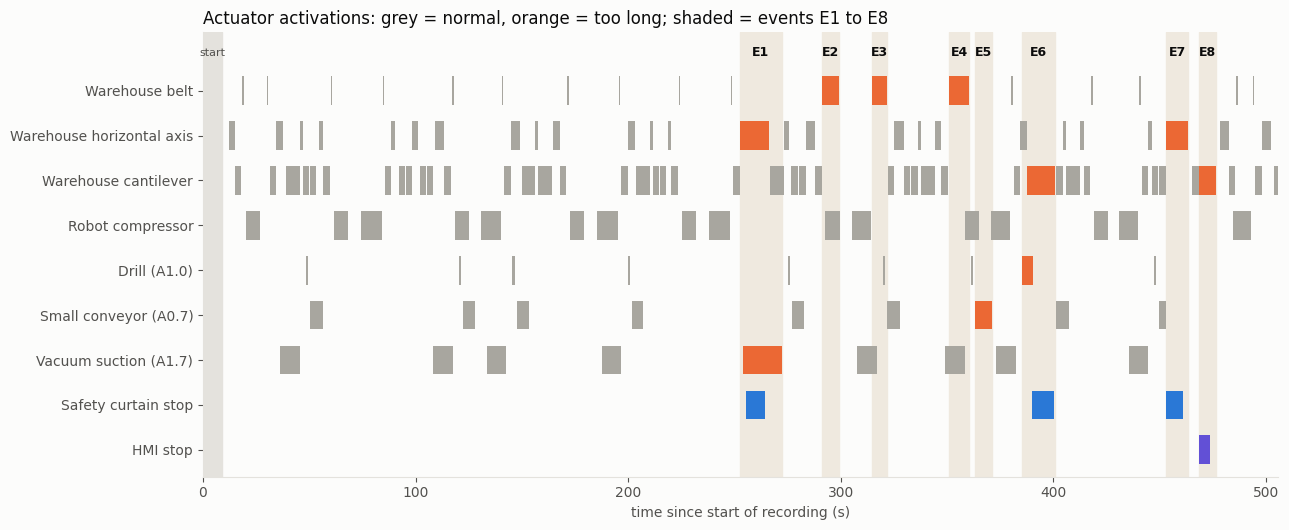

In [20]:
ROWS = [
    ("Warehouse belt", "Beckhoff",
     ["WH.Q1_beltForward", "WH.Q2_beltBackward"]),
    ("Warehouse horizontal axis", "Beckhoff",
     ["WH.Q3_horRack", "WH.Q4_horBelt"]),
    ("Warehouse cantilever", "Beckhoff",
     ["WH.Q7_cantForw", "WH.Q8_cantBack"]),
    ("Robot compressor", "Beckhoff", ["VG.Q7_compressorON"]),
    ("Drill (A1.0)", "Siemens", ["A1.0"]),
    ("Small conveyor (A0.7)", "Siemens", ["A0.7"]),
    ("Vacuum suction (A1.7)", "Siemens", ["A1.7"]),
]
fig, ax = plt.subplots(figsize=(13, 5.4))
labels = [r[0] for r in ROWS] + ["Safety curtain stop", "HMI stop"]
for y, (label, plc, signals) in enumerate(ROWS):
    part = acts[acts["signal"].isin(signals)]
    for _, a in part.iterrows():
        flagged = (a["signal"], a["start"]) in flag_keys
        ax.broken_barh([(a["start"], a["duration"])], (y - 0.32, 0.64),
                       facecolors=C_FLAG if flagged else C_NORMAL)
for y, prefix, colour in ((len(ROWS), "Safety", C_SAFETY),
                          (len(ROWS) + 1, "HMI", C_HMI)):
    part = causes[causes["cause"].str.startswith(prefix)]
    ax.broken_barh(list(zip(part["start"], part["duration"])),
                   (y - 0.32, 0.64), facecolors=colour)
for _, ev in events.iterrows():
    ax.axvspan(ev["start_s"], ev["end_s"], color="#efe9df", zorder=0)
    ax.text((ev["start_s"] + ev["end_s"]) / 2, -0.85, ev["event"],
            ha="center", va="center", fontsize=9, fontweight="bold")
ax.axvspan(0, PRODUCTION_START, color=GRID, zorder=0)
ax.text(PRODUCTION_START / 2, -0.85, "start", ha="center", va="center",
        fontsize=8, color=INK_2)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.set_ylim(len(labels) - 0.4, -1.3)
ax.set_xlim(0, RECORDING_END)
ax.set_xlabel("time since start of recording (s)")
ax.set_title("Actuator activations: grey = normal, orange = too long; "
             "shaded = events E1 to E8", loc="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_event_timeline.png", dpi=160)
show(fig)

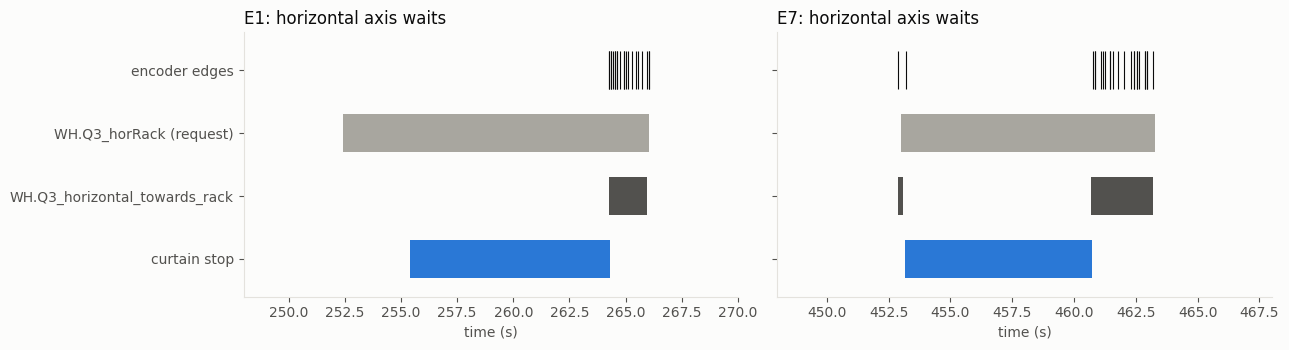

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
panels = [(248, 270, "E1"), (448, 468, "E7")]
for ax, (lo, hi, name) in zip(axes, panels):
    tracks = [
        ("WH.Q3_horRack", bec["WH.Q3_horRack"], C_NORMAL),
        ("WH.Q3_horizontal_towards_rack",
         bec["WH.Q3_horizontal_towards_rack"], INK_2),
        ("Safety curtain stop", ~sie["A201.0"].astype(bool), C_SAFETY),
    ]
    for y, (label, signal, colour) in enumerate(tracks):
        times = sie["t"] if label.startswith("Safety") else bec["t"]
        spans = [(s, e - s) for s, e in on_intervals(times, signal)
                 if overlap(s, e, lo, hi)]
        ax.broken_barh(spans, (y + 1 - 0.3, 0.6), facecolors=colour)
    window = pulse_times[(pulse_times >= lo) & (pulse_times <= hi)]
    ax.vlines(window, -0.3, 0.3, color=INK, linewidth=0.8)
    ax.set_xlim(lo, hi)
    ax.set_title(f"{name}: horizontal axis waits", loc="left")
    ax.set_xlabel("time (s)")
axes[0].set_yticks(range(4))
axes[0].set_yticklabels(["encoder edges", "WH.Q3_horRack (request)",
                         "WH.Q3_horizontal_towards_rack", "curtain stop"])
axes[0].set_ylim(3.6, -0.6)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_stall_evidence.png", dpi=160)
show(fig)

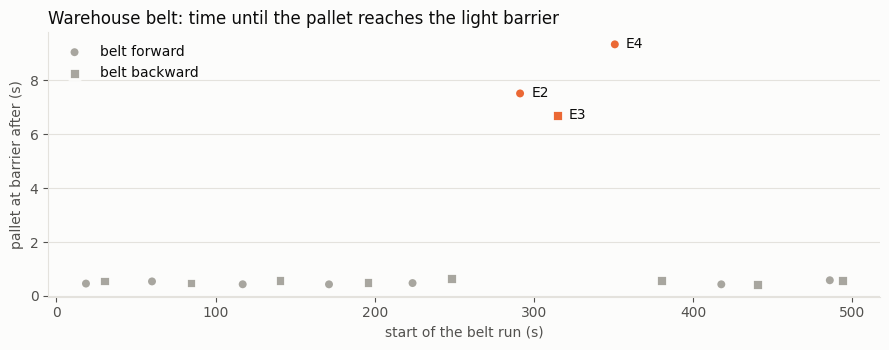

In [22]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for signal, marker, label in (("WH.Q1_beltForward", "o", "belt forward"),
                              ("WH.Q2_beltBackward", "s", "belt backward")):
    part = belt[belt["signal"] == signal]
    colours = [C_FLAG if f else C_NORMAL for f in part["flagged"]]
    ax.scatter(part["start"], part["barrier_reached_after_s"], s=60,
               c=colours, marker=marker, edgecolors="#fcfcfb",
               linewidths=2, label=label)
for _, b in belt[belt["flagged"]].iterrows():
    name = flags.loc[flags["start"] == b["start"], "event"].iloc[0]
    ax.annotate(name, (b["start"], b["barrier_reached_after_s"]),
                xytext=(8, 0), textcoords="offset points", va="center")
ax.set_xlabel("start of the belt run (s)")
ax.set_ylabel("pallet at barrier after (s)")
ax.set_title("Warehouse belt: time until the pallet reaches the light "
             "barrier", loc="left")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", color=GRID)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_belt_arrival.png", dpi=160)
show(fig)

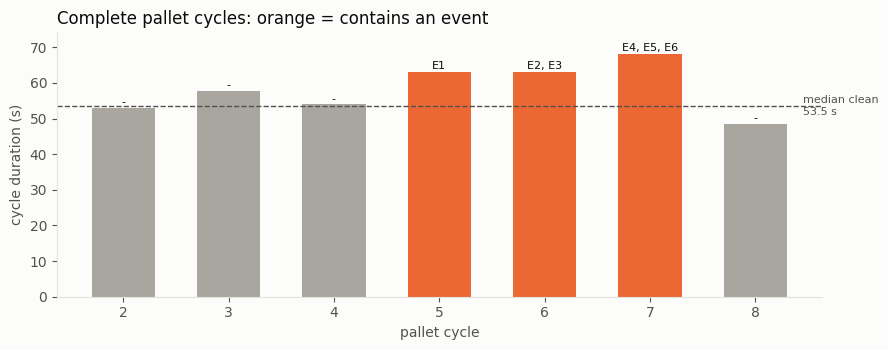

In [23]:
fig, ax = plt.subplots(figsize=(9, 3.6))
colours = [C_FLAG if e else C_NORMAL for e in done["events"]]
ax.bar(done["cycle"], done["duration_s"], color=colours, width=0.6)
ax.axhline(baseline, color=INK_2, linestyle="--", linewidth=1)
ax.text(done["cycle"].max() + 0.45, baseline, f"median clean\n"
        f"{baseline:.1f} s", va="center", fontsize=8, color=INK_2)
for _, c in done.iterrows():
    ax.text(c["cycle"], c["duration_s"] + 0.8, c["events"] or "-",
            ha="center", fontsize=8)
ax.set_xticks(done["cycle"])
ax.set_xlabel("pallet cycle")
ax.set_ylabel("cycle duration (s)")
ax.set_ylim(0, done["duration_s"].max() + 6)
ax.set_title("Complete pallet cycles: orange = contains an event",
             loc="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_cycle_durations.png", dpi=160)
show(fig)

## Phase 6 – Deployment: save the results

The tables are saved so the presentation, the README and the next
mini-project use exactly the same numbers.

In [24]:
hypotheses = pd.DataFrame([
    ("H1", "Data understanding", "PLC clocks are in sync",
     H1_ACCEPTED, f"7 shared safety edges, max difference "
     f"{max_offset:.3f} s <= {SYNC_TOLERANCE_S:.3f} s"),
    ("H2", "Data understanding", "Machine repeats one cycle",
     H2_ACCEPTED, f"{len(complete_cycles)} complete cycles, each 1 belt "
     f"forward, 1 belt backward, 2 robot moves"),
    ("H3", "Modelling", "Losses = activations far longer than normal",
     H3_ACCEPTED, f"{len(flags)} activations, {n_events} events; same "
     f"count for k = 1.5 and 3"),
    ("H4", "Evaluation", "Detections are real (no gap, no distance)",
     H4_ACCEPTED, f"worst-case excess >= "
     f"{flags['worst_case_excess_s'].min():.2f} s; above longest normal "
     f">= {flags['above_longest_normal_s'].min():.2f} s"),
    ("H5", "Evaluation", "Extra time is a standstill (short stop)",
     f"{n_standstill} of {len(events)}", "motor output OFF and encoder "
     "silent; belt/conveyor/drill have no motion sensor"),
    ("H6", "Evaluation", "Cause visible (curtain or HMI stop)",
     f"{n_cause} of {len(events)}", "3 safety curtain stops ended by "
     "reset, 1 HMI stop; E2-E5 no cause signal"),
    ("H7", "Evaluation", "Events make the pallet cycle longer",
     H7_ACCEPTED, f"exact permutation test p = {p_value:.3f}, "
     f"+{extra_total:.1f} s over 3 cycles"),
    ("H8", "Evaluation", "No stop is missed",
     H8_ACCEPTED, f"all {len(long_quiet)} long quiet periods explained"),
], columns=["id", "crisp_dm_phase", "hypothesis", "accepted", "evidence"])

events.round(2).to_csv(RESULTS_DIR / "performance_loss_events.csv",
                       index=False)
flags.round(3).to_csv(RESULTS_DIR / "long_activations.csv", index=False)
done.round(2).to_csv(RESULTS_DIR / "pallet_cycles.csv", index=False)
hypotheses.to_csv(RESULTS_DIR / "hypothesis_results.csv", index=False)
print(hypotheses.to_string(index=False))
print("\nSaved to", RESULTS_DIR)

id     crisp_dm_phase                                  hypothesis accepted                                                                       evidence
H1 Data understanding                      PLC clocks are in sync     True                       7 shared safety edges, max difference 0.091 s <= 0.169 s
H2 Data understanding                   Machine repeats one cycle     True         7 complete cycles, each 1 belt forward, 1 belt backward, 2 robot moves
H3          Modelling Losses = activations far longer than normal     True                         10 activations, 8 events; same count for k = 1.5 and 3
H4         Evaluation   Detections are real (no gap, no distance)     True                    worst-case excess >= 2.06 s; above longest normal >= 1.96 s
H5         Evaluation     Extra time is a standstill (short stop)   4 of 8 motor output OFF and encoder silent; belt/conveyor/drill have no motion sensor
H6         Evaluation         Cause visible (curtain or HMI stop)   4 of 8  

## Summary

**Found: 8 performance-loss events** in the production window
(8.9 to 505.8 s).

- E1 (252 s, 10.5 s lost): safety curtain stop. Warehouse horizontal
  axis and drilling-station vacuum suction wait. The axis was already
  waiting 3.0 s before the curtain signal.
- E2 (291 s, 6.9 s): warehouse belt forward, pallet 7.5 s late at the
  outside barrier. No cause signal.
- E3 (315 s, 6.2 s): warehouse belt backward, pallet 6.7 s late at the
  inside barrier. No cause signal.
- E4 (351 s, 8.8 s): warehouse belt forward, pallet 9.3 s late. No
  cause signal.
- E5 (363 s, 2.2 s): drilling-station small conveyor, part 1.6 s late
  at its barrier. No cause signal. Weakest detection.
- E6 (385 s, 10.4 s): drill ON 4 s too long, then safety curtain stop.
  Warehouse cantilever waits.
- E7 (453 s, 7.2 s): safety curtain stop. Warehouse horizontal axis
  waits.
- E8 (468 s, 4.9 s): HMI stop. Warehouse cantilever waits.

**What this means for choosing a model (next step):**

- There are 7 complete cycles, 677 activations and no labels, so a
  supervised or deep-learning model (e.g. LSTM) cannot be trained or
  validated on this sample.
- The useful unit is the **activation** (one step of one output) with
  its duration, not the raw 50 ms grid. A model should work on this
  table.
- The rule-based detector gives a transparent **baseline** and the
  8 events as **reference labels**. Any model chosen next (for example
  an unsupervised outlier model on activation durations, or clustering
  of cycles) must at least find these 8 events, without extra events
  that H8 shows do not exist.